# Phase 5 — Statistical Analysis
## Australian Stock Market Analytics

This notebook performs careful statistical analysis of the 53-company cross-sectional dataset.

Analyses include:
- distribution shape and normality diagnostics;
- Pearson and Spearman correlation with p-values;
- confidence intervals for descriptive estimates;
- market-cap group comparisons where sample sizes permit;
- outlier sensitivity checks;
- multiple-testing adjustment.

**Limitations:** this is a small, observational, cross-sectional dataset. Results show associations, not causation. Normality tests have limited power at this sample size. Statistical significance does not imply practical or investment significance. No historical time series is created.

## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Imports successful.")

Imports successful.


## 2. Load Phase 3 dataset

In [2]:
INPUT_FILENAME = "australian_stocks_feature_engineered.csv"
PROJECT_ROOT = None
input_file = None

for base in [Path.cwd(), *Path.cwd().parents]:
    candidate = base / "data" / "processed" / INPUT_FILENAME
    if candidate.exists():
        PROJECT_ROOT, input_file = base, candidate
        break

if input_file is None:
    raise FileNotFoundError(
        f"Cannot find {INPUT_FILENAME}. Run Phase 3 first and save it in data/processed/."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
STATS_DIR = PROJECT_ROOT / "reports" / "statistical_analysis"
STATS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(input_file)
print("Input:", input_file)
print("Shape:", df.shape)
print("Unique tickers:", df["ticker"].nunique())
display(df.head())

Input: e:\Projects\Australian Stock Market Data Science Project\data\processed\australian_stocks_feature_engineered.csv
Shape: (53, 47)
Unique tickers: 53


,ticker,company_name,total_shares,market_cap_m,eps_2h2024,eps_1h2025,eps_ltm,eps_ap_24_25,pe_annual_report,pe_ltm,price,book_value_per_share,week52_range,duplicate_ticker_flag,annual_pe_missing,week52_low,week52_high,market_cap_m_original,eps_ltm_original,pe_ltm_original,total_shares_outlier,market_cap_m_outlier,eps_ltm_outlier,eps_ap_24_25_outlier,pe_ltm_outlier,price_outlier,book_value_per_share_outlier,week52_range_valid,log_market_cap_m,market_cap_size_band,eps_half_year_difference,eps_ltm_vs_annual_difference,eps_ltm_vs_annual_pct_difference,earnings_yield_pct,price_to_book,pe_ltm_minus_annual,pe_ltm_vs_annual_pct_difference,week52_range_width,price_position_52w,price_distance_from_52w_low_pct,price_distance_from_52w_high_pct,price_outside_52w_range,annual_pe_missing_flag,negative_ltm_eps_flag,negative_ltm_pe_flag,nonpositive_book_value_flag,invalid_52w_range_flag
0,VEA,Viva Energy Group Ltd,1625651926,"3,511.4082",-0.3000,12.3000,12.0000,4.8000,450.0000,18.0000,2.1600,1.0270,1.41 - 2.83,False,False,1.4100,2.8300,"3,511.4082",12.0000,18.0000,False,False,False,False,False,False,False,True,8.1638,Medium (sample-relative),12.6000,7.2000,150.0000,5.5556,2.1032,-432.0000,-96.0000,1.4200,0.5282,53.1915,23.6749,False,False,False,False,False,False
1,DDR,Dicker Data Ltd,180817855,"1,871.4648",23.9700,21.7900,45.7600,43.6200,237.2765,22.6180,10.3500,1.3890,7.58 - 10.94,False,False,7.5800,10.9400,"1,871.4648",45.7600,22.6180,False,False,False,False,False,False,False,True,7.5345,Medium (sample-relative),-2.1800,2.1400,4.9060,4.4213,7.4514,-214.6585,-90.4677,3.3600,0.8244,36.5435,5.3931,False,False,False,False,False,False
2,FMG,Fortescue Metals Group Ltd,3078964918,"68,075.9143",50.5000,39.5500,90.0500,109.7000,201.5497,24.5530,22.1100,9.8740,13.18 - 22.11,False,False,13.1800,22.1100,"68,075.9143",90.0500,24.5530,True,True,False,False,False,False,False,True,11.1284,Large (sample-relative),-10.9500,-19.6500,-17.9125,4.0728,2.2392,-176.9967,-87.8179,8.9300,1.0000,67.7542,0.0000,False,False,False,False,False,False
3,RIO,RIO Tinto Ltd,371216214,"51,402.3092",315.2000,296.0000,611.2000,669.5000,206.8260,22.6554,138.4700,54.4740,100.75 - 140.58,False,False,100.7500,140.5800,"51,402.3092",611.2000,22.6554,False,True,True,True,False,True,True,True,10.8474,Large (sample-relative),-19.2000,-58.3000,-8.7080,4.4140,2.5419,-184.1706,-89.0461,39.8300,0.9470,37.4392,1.5009,False,False,False,False,False,False
4,APE,Eagers Automotive Ltd,282364338,"7,578.6588",34.8000,46.4000,81.2000,80.2000,334.6633,33.0542,26.8400,4.6360,10.90 - 35.64,False,False,10.9000,35.6400,"7,578.6588",81.2000,33.0542,False,False,False,False,False,False,False,True,8.9331,Medium (sample-relative),11.6000,1.0000,1.2469,3.0253,5.7895,-301.6092,-90.1232,24.7400,0.6443,146.2385,24.6914,False,False,False,False,False,False


## 3. Validate schema and prepare numeric columns

In [3]:
required = [
    "ticker", "company_name", "market_cap_m", "eps_ltm", "eps_ap_24_25",
    "pe_ltm", "pe_annual_report", "price", "book_value_per_share",
    "price_to_book", "earnings_yield_pct", "market_cap_size_band"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if df["ticker"].duplicated().any():
    raise ValueError("Duplicate tickers found; recheck Phase 2.")

numeric_cols = [
    "market_cap_m", "eps_ltm", "eps_ap_24_25", "pe_ltm",
    "pe_annual_report", "price", "book_value_per_share",
    "price_to_book", "earnings_yield_pct", "price_position_52w"
]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Schema validation passed.")
print("Rows:", len(df), "| Unique tickers:", df["ticker"].nunique())

Schema validation passed.
Rows: 53 | Unique tickers: 53


## 4. Descriptive statistics and shape diagnostics
Skewness and kurtosis describe distribution shape. Normality tests are diagnostic only and can be sensitive to outliers.

In [4]:
analysis_cols = [
    c for c in [
        "market_cap_m", "eps_ltm", "eps_ap_24_25", "pe_ltm",
        "pe_annual_report", "price", "book_value_per_share",
        "price_to_book", "earnings_yield_pct", "price_position_52w"
    ] if c in df.columns
]

shape_rows = []
for col in analysis_cols:
    x = df[col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) >= 3:
        shapiro_stat, shapiro_p = stats.shapiro(x) if len(x) <= 5000 else (np.nan, np.nan)
        shape_rows.append({
            "variable": col,
            "n": len(x),
            "mean": x.mean(),
            "median": x.median(),
            "std": x.std(ddof=1),
            "skewness": stats.skew(x, bias=False),
            "excess_kurtosis": stats.kurtosis(x, fisher=True, bias=False),
            "shapiro_statistic": shapiro_stat,
            "shapiro_p_value": shapiro_p
        })

shape_summary = pd.DataFrame(shape_rows)
display(shape_summary)
shape_summary.to_csv(STATS_DIR / "distribution_shape_and_normality.csv", index=False)

,variable,n,mean,median,std,skewness,excess_kurtosis,shapiro_statistic,shapiro_p_value
0,market_cap_m,53,"22,267.2389","3,484.5029","46,043.1047",3.2774,12.7340,0.5387,0.0000
1,eps_ltm,53,125.1825,27.2000,271.3879,3.8181,16.4261,0.4906,0.0000
2,eps_ap_24_25,53,127.1736,27.7300,272.1159,3.7873,16.0993,0.4842,0.0000
3,pe_ltm,53,40.2082,18.6480,120.5996,6.4409,44.4996,0.2917,0.0000
4,pe_annual_report,51,445.8107,190.4430,"1,215.0219",6.4731,44.1182,0.2740,0.0000
5,price,53,22.5255,7.7500,39.5430,3.0087,9.3334,0.5735,0.0000
6,book_value_per_share,53,8.9558,3.5350,15.5633,3.6677,15.6631,0.5508,0.0000
7,price_to_book,53,2.6108,1.8114,2.2023,1.6129,2.0456,0.8037,0.0000
8,earnings_yield_pct,52,11.3101,5.3324,20.8654,3.5873,13.0108,0.4560,0.0000
9,price_position_52w,52,0.5134,0.5879,0.3022,-0.1672,-1.2830,0.9371,0.0086


## 5. Visual diagnostics for selected variables
Histograms and Q-Q plots help inspect shape; they do not prove a distribution is normal or non-normal.

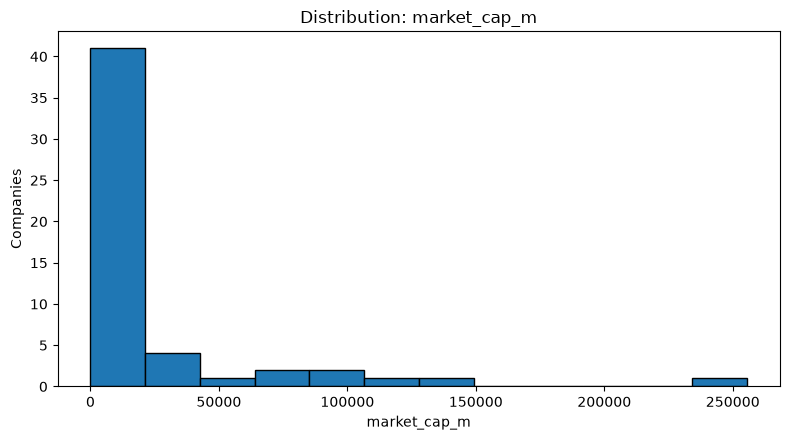

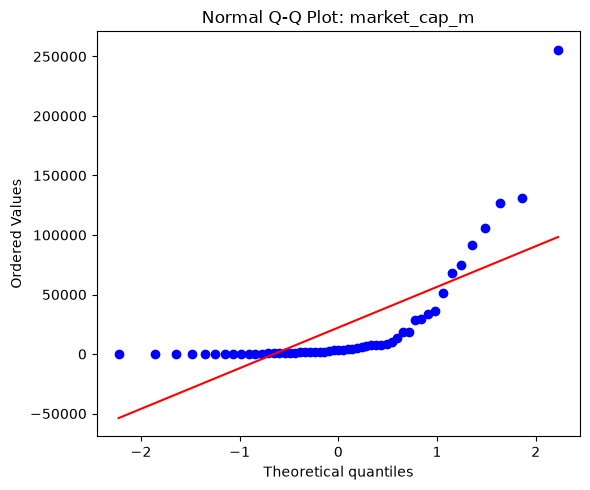

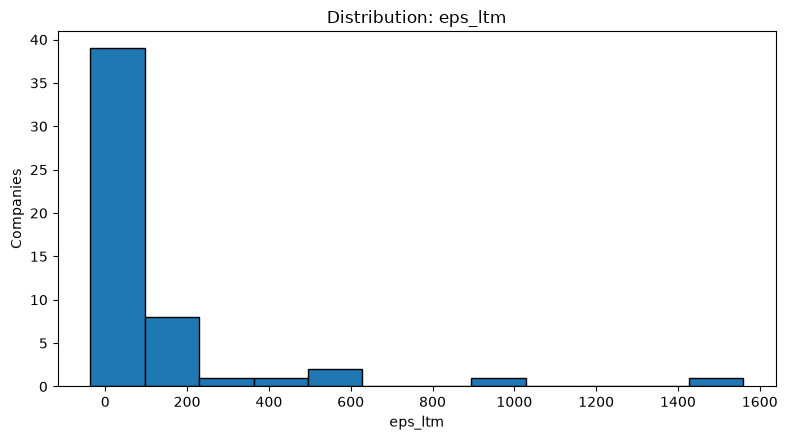

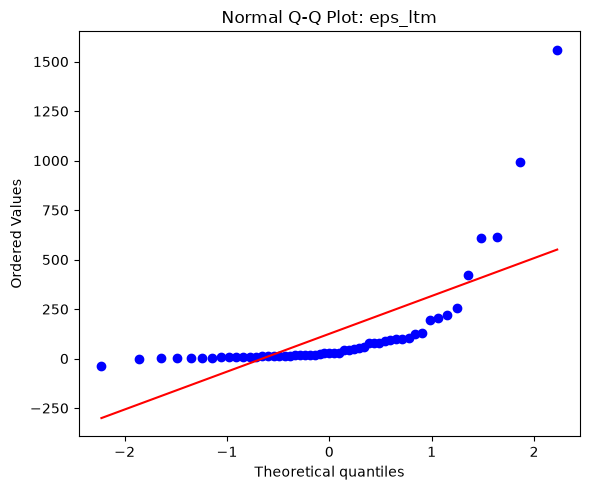

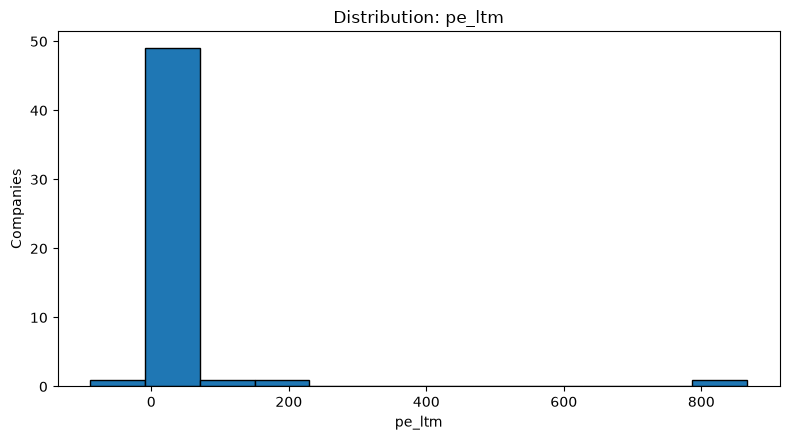

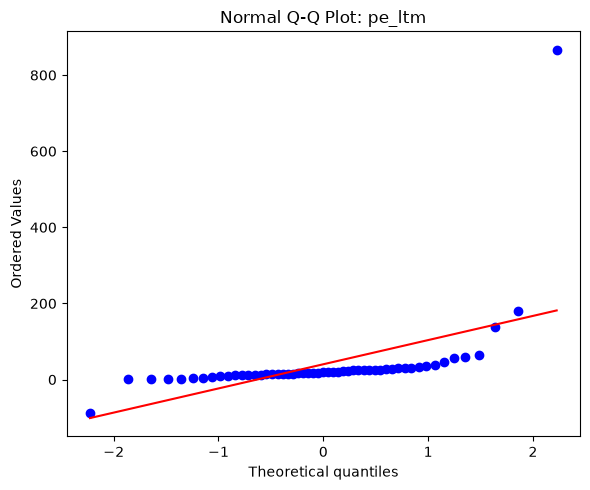

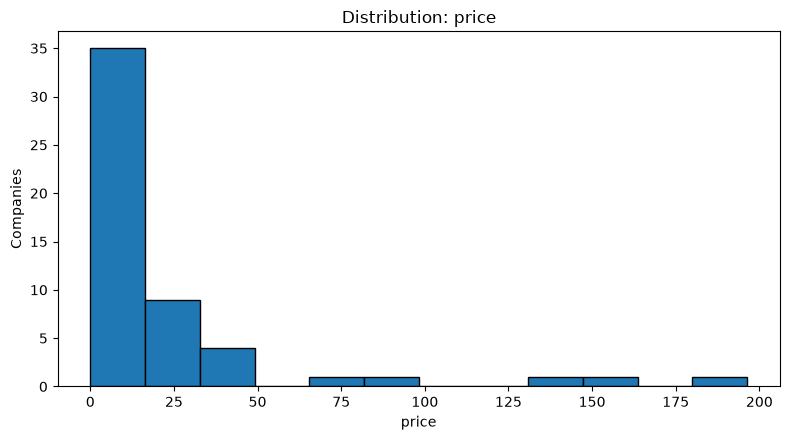

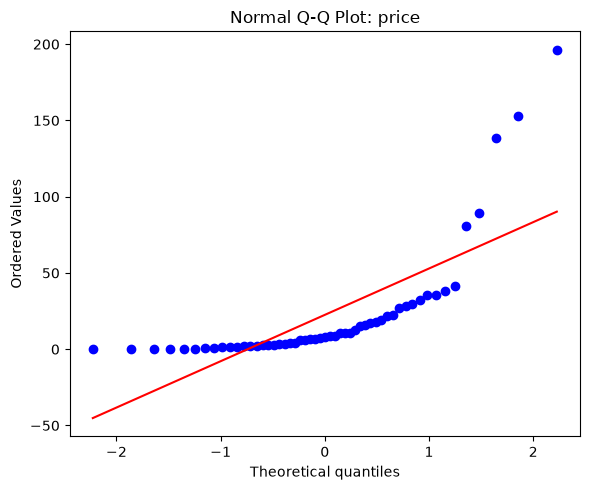

In [5]:
for col in ["market_cap_m", "eps_ltm", "pe_ltm", "price"]:
    x = df[col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) == 0:
        continue
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(x, bins=12, edgecolor="black")
    ax.set(title=f"Distribution: {col}", xlabel=col, ylabel="Companies")
    plt.tight_layout()
    plt.show()

    if len(x) >= 3:
        fig, ax = plt.subplots(figsize=(6, 5))
        stats.probplot(x, dist="norm", plot=ax)
        ax.set_title(f"Normal Q-Q Plot: {col}")
        plt.tight_layout()
        plt.show()

## 6. Pearson and Spearman correlation with p-values
For each pair, calculate correlation and its p-value using pairwise complete observations. P-values are descriptive evidence under test assumptions; the small sample and potential outliers should be considered.

In [6]:
corr_vars = [
    c for c in [
        "market_cap_m", "eps_ltm", "eps_ap_24_25", "pe_ltm",
        "pe_annual_report", "price", "book_value_per_share",
        "price_to_book", "earnings_yield_pct", "price_position_52w"
    ] if c in df.columns
]

def pairwise_correlations(data, method="pearson"):
    rows = []
    for i, x_col in enumerate(data.columns):
        for y_col in data.columns[i + 1:]:
            pair = data[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
            n = len(pair)
            if n < 3 or pair[x_col].nunique() < 2 or pair[y_col].nunique() < 2:
                r, p = np.nan, np.nan
            else:
                if method == "pearson":
                    r, p = stats.pearsonr(pair[x_col], pair[y_col])
                else:
                    r, p = stats.spearmanr(pair[x_col], pair[y_col])
            rows.append({
                "method": method, "variable_1": x_col, "variable_2": y_col,
                "n": n, "correlation": r, "p_value": p
            })
    return pd.DataFrame(rows)

corr_data = df[corr_vars]
pearson_results = pairwise_correlations(corr_data, "pearson")
spearman_results = pairwise_correlations(corr_data, "spearman")
display(pearson_results.sort_values("p_value").head(15))
display(spearman_results.sort_values("p_value").head(15))

pearson_results.to_csv(STATS_DIR / "pearson_correlations_pvalues.csv", index=False)
spearman_results.to_csv(STATS_DIR / "spearman_correlations_pvalues.csv", index=False)

,method,variable_1,variable_2,n,correlation,p_value
9,pearson,eps_ltm,eps_ap_24_25,53,0.9984,0.0000
24,pearson,pe_ltm,pe_annual_report,51,0.9831,0.0000
35,pearson,price,book_value_per_share,53,0.9248,0.0000
4,pearson,market_cap_m,price,53,0.6574,0.0000
19,pearson,eps_ap_24_25,price,53,0.6489,0.0000
20,pearson,eps_ap_24_25,book_value_per_share,53,0.6451,0.0000
12,pearson,eps_ltm,price,53,0.6399,0.0000
13,pearson,eps_ltm,book_value_per_share,53,0.6374,0.0000
5,pearson,market_cap_m,book_value_per_share,53,0.5890,0.0000
0,pearson,market_cap_m,eps_ltm,53,0.4110,0.0022


,method,variable_1,variable_2,n,correlation,p_value
28,spearman,pe_ltm,earnings_yield_pct,52,-1.0000,0.0000
9,spearman,eps_ltm,eps_ap_24_25,53,0.9547,0.0000
35,spearman,price,book_value_per_share,53,0.8955,0.0000
33,spearman,pe_annual_report,earnings_yield_pct,50,-0.8656,0.0000
19,spearman,eps_ap_24_25,price,53,0.8488,0.0000
4,spearman,market_cap_m,price,53,0.8462,0.0000
20,spearman,eps_ap_24_25,book_value_per_share,53,0.8249,0.0000
12,spearman,eps_ltm,price,53,0.7723,0.0000
24,spearman,pe_ltm,pe_annual_report,51,0.7756,0.0000
13,spearman,eps_ltm,book_value_per_share,53,0.7530,0.0000


## 7. Adjust p-values for multiple testing
Testing many pairs increases the chance of false positives. Apply Benjamini–Hochberg false-discovery-rate correction within each correlation family.

In [7]:
def add_fdr_adjustment(results):
    out = results.copy()
    out["p_value_fdr"] = np.nan
    valid = out["p_value"].notna()
    if valid.any():
        out.loc[valid, "p_value_fdr"] = multipletests(
            out.loc[valid, "p_value"], method="fdr_bh"
        )[1]
    out["significant_fdr_0_05"] = out["p_value_fdr"] < 0.05
    return out

pearson_results = add_fdr_adjustment(pearson_results)
spearman_results = add_fdr_adjustment(spearman_results)

pearson_results.to_csv(STATS_DIR / "pearson_correlations_pvalues.csv", index=False)
spearman_results.to_csv(STATS_DIR / "spearman_correlations_pvalues.csv", index=False)

print("Pearson pairs significant after FDR correction:", int(pearson_results["significant_fdr_0_05"].fillna(False).sum()))
print("Spearman pairs significant after FDR correction:", int(spearman_results["significant_fdr_0_05"].fillna(False).sum()))
display(pearson_results.sort_values("p_value_fdr").head(15))

Pearson pairs significant after FDR correction: 11
Spearman pairs significant after FDR correction: 31


,method,variable_1,variable_2,n,correlation,p_value,p_value_fdr,significant_fdr_0_05
9,pearson,eps_ltm,eps_ap_24_25,53,0.9984,0.0000,0.0000,True
24,pearson,pe_ltm,pe_annual_report,51,0.9831,0.0000,0.0000,True
35,pearson,price,book_value_per_share,53,0.9248,0.0000,0.0000,True
4,pearson,market_cap_m,price,53,0.6574,0.0000,0.0000,True
19,pearson,eps_ap_24_25,price,53,0.6489,0.0000,0.0000,True
20,pearson,eps_ap_24_25,book_value_per_share,53,0.6451,0.0000,0.0000,True
12,pearson,eps_ltm,price,53,0.6399,0.0000,0.0000,True
13,pearson,eps_ltm,book_value_per_share,53,0.6374,0.0000,0.0000,True
5,pearson,market_cap_m,book_value_per_share,53,0.5890,0.0000,0.0000,True
1,pearson,market_cap_m,eps_ap_24_25,53,0.4108,0.0022,0.0092,True


## 8. Bootstrap confidence intervals for selected means and medians
Bootstrap intervals describe sampling uncertainty under the assumption that these companies can be treated as representative observations. Since the data may not be a random sample of all Australian listed companies, interpret the intervals cautiously.

In [8]:
rng = np.random.default_rng(42)

def bootstrap_ci(values, statistic=np.mean, n_boot=5000, confidence=0.95):
    x = pd.Series(values).replace([np.inf, -np.inf], np.nan).dropna().to_numpy(dtype=float)
    if len(x) < 2:
        return {"n": len(x), "estimate": np.nan, "ci_lower": np.nan, "ci_upper": np.nan}
    estimates = np.empty(n_boot)
    for i in range(n_boot):
        sample = rng.choice(x, size=len(x), replace=True)
        estimates[i] = statistic(sample)
    alpha = 1 - confidence
    return {
        "n": len(x),
        "estimate": float(statistic(x)),
        "ci_lower": float(np.quantile(estimates, alpha / 2)),
        "ci_upper": float(np.quantile(estimates, 1 - alpha / 2))
    }

ci_rows = []
for col in ["market_cap_m", "eps_ltm", "price", "price_to_book"]:
    for stat_name, stat_func in [("mean", np.mean), ("median", np.median)]:
        result = bootstrap_ci(df[col], statistic=stat_func)
        ci_rows.append({"variable": col, "statistic": stat_name, **result})

bootstrap_results = pd.DataFrame(ci_rows)
display(bootstrap_results)
bootstrap_results.to_csv(STATS_DIR / "bootstrap_confidence_intervals.csv", index=False)

,variable,statistic,n,estimate,ci_lower,ci_upper
0,market_cap_m,mean,53,"22,267.2389","11,424.3876","36,304.0684"
1,market_cap_m,median,53,"3,484.5029","1,588.5937","7,578.6588"
2,eps_ltm,mean,53,125.1825,62.6111,206.0620
3,eps_ltm,median,53,27.2000,16.2600,57.4700
4,price,mean,53,22.5255,13.1152,33.7948
5,price,median,53,7.7500,4.0700,15.4300
6,price_to_book,mean,53,2.6108,2.0598,3.2207
7,price_to_book,median,53,1.8114,1.5376,2.2392


## 9. Market-cap group comparisons
Compare selected indicators across the dataset-relative market-cap bands. Kruskal–Wallis is used as a nonparametric omnibus test; groups with fewer than two usable observations are excluded, and tests with fewer than two usable groups are reported as unavailable. These comparisons are exploratory.

In [9]:
group_col = "market_cap_size_band"
group_tests = []

for metric in ["eps_ltm", "pe_ltm", "price_to_book", "price_position_52w"]:
    if metric not in df.columns:
        continue
    groups = []
    group_names = []
    for name, group in df.groupby(group_col, observed=False, dropna=True):
        values = pd.to_numeric(group[metric], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna().to_numpy()
        if len(values) >= 2:
            groups.append(values)
            group_names.append(str(name))
    if len(groups) >= 2:
        statistic, p_value = stats.kruskal(*groups)
    else:
        statistic, p_value = np.nan, np.nan
    group_tests.append({
        "metric": metric,
        "test": "Kruskal-Wallis",
        "groups_included": "; ".join(group_names),
        "number_of_groups": len(groups),
        "statistic": statistic,
        "p_value": p_value
    })

group_test_results = pd.DataFrame(group_tests)
valid = group_test_results["p_value"].notna()
group_test_results["p_value_fdr"] = np.nan
if valid.any():
    group_test_results.loc[valid, "p_value_fdr"] = multipletests(
        group_test_results.loc[valid, "p_value"], method="fdr_bh"
    )[1]
display(group_test_results)
group_test_results.to_csv(STATS_DIR / "market_cap_group_tests.csv", index=False)

,metric,test,groups_included,number_of_groups,statistic,p_value,p_value_fdr
0,eps_ltm,Kruskal-Wallis,Large (sample-relative); Medium (sample-relati...,3,19.1065,0.0001,0.0003
1,pe_ltm,Kruskal-Wallis,Large (sample-relative); Medium (sample-relati...,3,8.2145,0.0165,0.0219
2,price_to_book,Kruskal-Wallis,Large (sample-relative); Medium (sample-relati...,3,13.4816,0.0012,0.0024
3,price_position_52w,Kruskal-Wallis,Large (sample-relative); Medium (sample-relati...,3,3.9331,0.1399,0.1399


## 10. Outlier sensitivity analysis
Compare mean and median before/after a descriptive IQR-based filter. This is a sensitivity check only: the main dataset is not changed, and flagged observations are not deleted from the saved data.

In [10]:
sensitivity_rows = []
for col in ["market_cap_m", "eps_ltm", "pe_ltm", "price", "price_to_book"]:
    x = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if len(x) < 4:
        continue
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    filtered = x[(x >= low) & (x <= high)]
    sensitivity_rows.append({
        "variable": col,
        "n_original": len(x),
        "n_within_iqr_fences": len(filtered),
        "n_flagged_for_sensitivity": len(x) - len(filtered),
        "mean_original": x.mean(),
        "mean_within_fences": filtered.mean(),
        "median_original": x.median(),
        "median_within_fences": filtered.median(),
        "iqr_lower_fence": low,
        "iqr_upper_fence": high
    })

sensitivity_results = pd.DataFrame(sensitivity_rows)
display(sensitivity_results)
sensitivity_results.to_csv(STATS_DIR / "outlier_sensitivity_analysis.csv", index=False)

,variable,n_original,n_within_iqr_fences,n_flagged_for_sensitivity,mean_original,mean_within_fences,median_original,median_within_fences,iqr_lower_fence,iqr_upper_fence
0,market_cap_m,53,45,8,"22,267.2389","6,111.1085","3,484.5029","1,858.4337","-26,113.6973","44,997.7377"
1,eps_ltm,53,47,6,125.1825,46.3355,27.2000,18.2000,-116.2500,224.1500
2,pe_ltm,53,46,7,40.2082,18.5461,18.6480,18.0883,-12.1961,52.5643
3,price,53,48,5,22.5255,11.1638,7.7500,6.7350,-27.5400,51.9000
4,price_to_book,53,46,7,2.6108,1.8889,1.8114,1.7463,-1.5101,5.6223


## 11. Optional association test: positive P/E and market cap
This examines Spearman association among companies with positive LTM P/E only. The subset rule is explicit because negative P/E values have a different interpretation.

In [11]:
subset = df[["market_cap_m", "pe_ltm"]].replace([np.inf, -np.inf], np.nan).dropna()
subset = subset[(subset["market_cap_m"] > 0) & (subset["pe_ltm"] > 0)]
if len(subset) >= 3 and subset["market_cap_m"].nunique() > 1 and subset["pe_ltm"].nunique() > 1:
    rho, p_value = stats.spearmanr(subset["market_cap_m"], subset["pe_ltm"])
else:
    rho, p_value = np.nan, np.nan

positive_pe_association = pd.DataFrame([{
    "subset": "positive market cap and positive LTM P/E",
    "n": len(subset),
    "spearman_rho": rho,
    "p_value": p_value
}])
display(positive_pe_association)
positive_pe_association.to_csv(STATS_DIR / "positive_pe_market_cap_association.csv", index=False)

,subset,n,spearman_rho,p_value
0,positive market cap and positive LTM P/E,52,0.4287,0.0015


## 12. Statistical analysis summary

In [12]:
summary = pd.DataFrame([{
    "rows": len(df),
    "unique_tickers": df["ticker"].nunique(),
    "duplicate_tickers": int(df["ticker"].duplicated().sum()),
    "variables_assessed_for_distribution": len(shape_summary),
    "pearson_pairs_tested": int(pearson_results["p_value"].notna().sum()),
    "pearson_pairs_fdr_significant": int(pearson_results["significant_fdr_0_05"].fillna(False).sum()),
    "spearman_pairs_tested": int(spearman_results["p_value"].notna().sum()),
    "spearman_pairs_fdr_significant": int(spearman_results["significant_fdr_0_05"].fillna(False).sum()),
    "group_tests_with_p_values": int(group_test_results["p_value"].notna().sum()),
    "missing_annual_pe": int(df["pe_annual_report"].isna().sum()),
    "invalid_52w_ranges": int(df["invalid_52w_range_flag"].sum()) if "invalid_52w_range_flag" in df else int(df["price_position_52w"].isna().sum())
}])
display(summary)
summary.to_csv(STATS_DIR / "statistical_analysis_summary.csv", index=False)
print("Outputs saved to:", STATS_DIR)
print("PHASE 5 STATISTICAL ANALYSIS COMPLETED. Interpret findings cautiously; statistical significance is not investment advice.")

,rows,unique_tickers,duplicate_tickers,variables_assessed_for_distribution,pearson_pairs_tested,pearson_pairs_fdr_significant,spearman_pairs_tested,spearman_pairs_fdr_significant,group_tests_with_p_values,missing_annual_pe,invalid_52w_ranges
0,53,53,0,10,45,11,45,31,4,2,1


Outputs saved to: e:\Projects\Australian Stock Market Data Science Project\reports\statistical_analysis
PHASE 5 STATISTICAL ANALYSIS COMPLETED. Interpret findings cautiously; statistical significance is not investment advice.
